<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/02_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

In [3]:
def extract_file_from_drive(zip_path, file_name, extract_to='/content/extracted'):

    os.makedirs(extract_to, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(
                f"{file_name} not found in the ZIP archive."
            )

        zip_ref.extract(file_name, extract_to)

    extracted_path = os.path.join(extract_to, file_name)

    return extracted_path

In [19]:
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [4]:
zip_path = "/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/raw/NGA_2025_HFCP_v01_M_CSV.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

['Raw_data_spatialrev.csv', 'level2_price_yellow_maize.csv', 'level2_price_yam.csv', 'level2_price_white_maize.csv', 'level2_price_white_beans.csv', 'level2_price_soybean.csv', 'level2_price_sorghum.csv', 'level2_price_local_rice.csv', 'level2_price_imported_rice.csv', 'level2_price_garri.csv', 'level2_price_brown_beans.csv']


In [5]:
csv_files = [
    'Raw_data_spatialrev.csv',
    'level2_price_yellow_maize.csv',
    'level2_price_yam.csv',
    'level2_price_white_maize.csv',
    'level2_price_white_beans.csv',
    'level2_price_soybean.csv',
    'level2_price_sorghum.csv',
    'level2_price_local_rice.csv',
    'level2_price_imported_rice.csv',
    'level2_price_garri.csv',
    'level2_price_brown_beans.csv'
]

dataframes = {}

for i, file_name in enumerate(csv_files, start=1):
    try:
        extracted_path = extract_file_from_drive(zip_path, file_name)
        df_name = f'df_{i}'
        globals()[df_name] = pd.read_csv(extracted_path)
        dataframes[df_name] = file_name
        print(f"Successfully loaded '{file_name}' into variable `{df_name}` (Shape: {globals()[df_name].shape})")
    except Exception as e:
        print(f"Failed to load {file_name}: {e}")

Successfully loaded 'Raw_data_spatialrev.csv' into variable `df_1` (Shape: (220214, 72))
Successfully loaded 'level2_price_yellow_maize.csv' into variable `df_2` (Shape: (190873, 25))
Successfully loaded 'level2_price_yam.csv' into variable `df_3` (Shape: (173180, 25))
Successfully loaded 'level2_price_white_maize.csv' into variable `df_4` (Shape: (199828, 25))
Successfully loaded 'level2_price_white_beans.csv' into variable `df_5` (Shape: (202059, 25))
Successfully loaded 'level2_price_soybean.csv' into variable `df_6` (Shape: (186293, 25))
Successfully loaded 'level2_price_sorghum.csv' into variable `df_7` (Shape: (185067, 25))
Successfully loaded 'level2_price_local_rice.csv' into variable `df_8` (Shape: (198630, 25))
Successfully loaded 'level2_price_imported_rice.csv' into variable `df_9` (Shape: (141612, 25))
Successfully loaded 'level2_price_garri.csv' into variable `df_10` (Shape: (202731, 25))
Successfully loaded 'level2_price_brown_beans.csv' into variable `df_11` (Shape: (17

In [6]:
print("Available DataFrame variables:")
for key, val in dataframes.items():
    print(f"{key}: {val}")

Available DataFrame variables:
df_1: Raw_data_spatialrev.csv
df_2: level2_price_yellow_maize.csv
df_3: level2_price_yam.csv
df_4: level2_price_white_maize.csv
df_5: level2_price_white_beans.csv
df_6: level2_price_soybean.csv
df_7: level2_price_sorghum.csv
df_8: level2_price_local_rice.csv
df_9: level2_price_imported_rice.csv
df_10: level2_price_garri.csv
df_11: level2_price_brown_beans.csv


### Baseline Analysis of `df_1` (Raw_data_spatialrev.csv)

In [7]:
# 1. General Overview of the dataset
print("=== Dataset Shape ===")
print(df_1.shape)

print("\n=== Info ===")
display(df_1.info(max_cols=100))

=== Dataset Shape ===
(220214, 72)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220214 entries, 0 to 220213
Data columns (total 72 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   fid           220214 non-null  int64  
 1   submissio     220214 non-null  int64  
 2   date          220214 non-null  object 
 3   zonecode1     220214 non-null  int64  
 4   geopol_zon    220214 non-null  object 
 5   statecode1    220214 non-null  int64  
 6   zonelabel1    220214 non-null  object 
 7   statelabel    220214 non-null  object 
 8   lga           220214 non-null  int64  
 9   lgalabel      220214 non-null  object 
 10  sector        220214 non-null  object 
 11  vc_id         220214 non-null  object 
 12  staff_vali    220214 non-null  int64  
 13  consent       220214 non-null  int64  
 14  market_typ    220214 non-null  object 
 15  price_cate    220214 non-null  object 
 16  market_tim    220214 non-null  int64  
 17 

None

In [8]:
# 2. Display the first few rows to examine data structure
display(df_1.head().T)

,0,1,2,3,4
fid,0,1,2,3,4
submissio,4316,5346,5541,5680,5690
date,12/1/2024,12/1/2024,12/2/2024,12/2/2024,12/2/2024
zonecode1,1,1,3,1,1
geopol_zon,nbsnorthcentral,nbsnorthcentral,nbsnorthwest,nbsnorthcentral,nbsnorthcentral
...,...,...,...,...,...
gps_coords,9.0266823 7.607355399999999 0.0 0.0,9.0266823 7.607355399999999 0.0 0.0,10.4607247 7.4472635 630.2872318788975 0.0,7.1928081 8.146351333333333 218.474 0.0,7.192811033333333 8.14631625 222.09 0.0
gps_latitu,9.026682,9.026682,10.460725,7.192808,7.192811
gps_longit,7.607355,7.607355,7.447264,8.146351,8.146316
gps_precis,NaN,NaN,NaN,NaN,NaN


In [9]:
# 3. Missing Value Analysis
missing_values = df_1.isnull().sum()
missing_percentage = (df_1.isnull().sum() / len(df_1)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

print("=== Columns with Missing Values ===")
if not missing_df.empty:
    display(missing_df)
else:
    print("No missing values found!")

=== Columns with Missing Values ===


,Missing Values,Percentage (%)
uom_import,63945,29.037663
q_rice,63945,29.037663
price_impo,63945,29.037663
price_impo_1,63945,29.037663
q_yam,36714,16.671965
uom_yam,36714,16.671965
price_yam_,36714,16.671965
price_yam,36714,16.671965
q_brownbea,28999,13.168554
price_br_1,28999,13.168554


In [10]:
# 4. Summary Statistics for numerical and categorical variables
print("=== Summary Statistics (Numerical) ===")
display(df_1.describe())

print("\n=== Summary Statistics (Categorical) ===")
display(df_1.describe(include=['object', 'category']))

=== Summary Statistics (Numerical) ===


,fid,submissio,zonecode1,statecode1,lga,staff_vali,consent,market_tim,uom_ymaize,q_ymaize,...,price_yam,price_yam_,uom_soyabe,q_soyabean,price_soya,price_so_2,gps_latitu,gps_longit,gps_precis,count
count,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,2.202140e+05,203418.000000,203418.00000,...,1.835000e+05,1.835000e+05,199310.000000,199310.000000,1.993100e+05,1.993100e+05,220214.000000,220214.000000,219218.000000,220214.0
mean,110106.500000,113258.710177,3.471292,19.347312,1946.054025,0.109984,0.999755,5.980224e+03,6.091645,1.05239,...,3.395627e+03,1.885100e+03,5.628720,1.048367,1.269427e+04,5.744930e+03,8.529373,7.287308,93.935890,1.0
std,63570.450427,63699.305641,1.758067,10.325774,1031.751518,0.312870,0.015657,1.842417e+06,20.959550,0.42878,...,1.899352e+05,1.899225e+05,19.809292,0.395232,1.881595e+06,1.334927e+06,2.514299,2.430840,453.606456,0.0
min,0.000000,189.000000,1.000000,1.000000,101.000000,0.000000,0.000000,-8.500000e+01,0.160000,1.00000,...,1.000000e+02,7.142857e+00,0.200000,1.000000,1.000000e+02,1.050000e+00,4.426009,2.714769,1.000000,1.0
25%,55053.250000,58209.250000,2.000000,10.000000,1019.000000,0.000000,1.000000,1.000000e+01,0.670000,1.00000,...,1.700000e+03,8.571429e+02,0.650000,1.000000,1.100000e+03,1.125000e+03,6.456500,5.264294,4.000000,1.0
50%,110106.500000,113306.500000,3.000000,19.000000,1944.000000,0.000000,1.000000,2.000000e+01,1.300000,1.00000,...,2.400000e+03,1.142857e+03,1.400000,1.000000,1.800000e+03,1.428571e+03,7.843022,7.336395,5.000000,1.0
75%,165159.750000,168395.750000,5.000000,28.000000,2806.000000,0.000000,1.000000,4.000000e+01,1.300000,1.00000,...,3.200000e+03,1.714286e+03,1.400000,1.000000,2.500000e+03,1.857143e+03,10.488568,8.529103,5.000000,1.0
max,220213.000000,223519.000000,6.000000,37.000000,3706.000000,1.000000,1.000000,6.584807e+08,100.000000,9.00000,...,8.135568e+07,8.135568e+07,100.000000,9.000000,8.033116e+08,5.737940e+08,13.754103,14.209325,6114.000000,1.0



=== Summary Statistics (Categorical) ===


,date,geopol_zon,zonelabel1,statelabel,lgalabel,sector,vc_id,market_typ,price_cate,maize_yell,maize_whit,sorghum,imported_r,local_rice,brown_bean,white_bean,garri_conf,yam_confir,soyabeans,gps_coords
count,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214
unique,217,6,6,37,591,2,901,10,4,3,3,3,3,3,3,3,3,3,3,214904
top,11/29/2024,nbsnorthwest,North West,KANO,AKURE SOUTH,Urban,BORNO2,RoadSide_shops_street vendors,Retail,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4.6880963 6.3161275 0.0 1700.0
freq,1452,45613,45923,9907,3945,151148,1039,67792,193398,203418,212848,206507,156269,211810,191215,217900,212002,183500,199310,72


clean dataset steps
1. drop the following columns: vc_id, gps_coord, consent, staff_valid, date_parsed, submission ID, LGA, state code, any one with the following prefix: uom, q.  zonecode1, geopol_zone, lga, price_wmai, price_sorg, price_impo, price_loca, price_brow, price_whit, price_garr, price_yam,  price_soya

### Geographical Distribution of Surveys in `df_1`

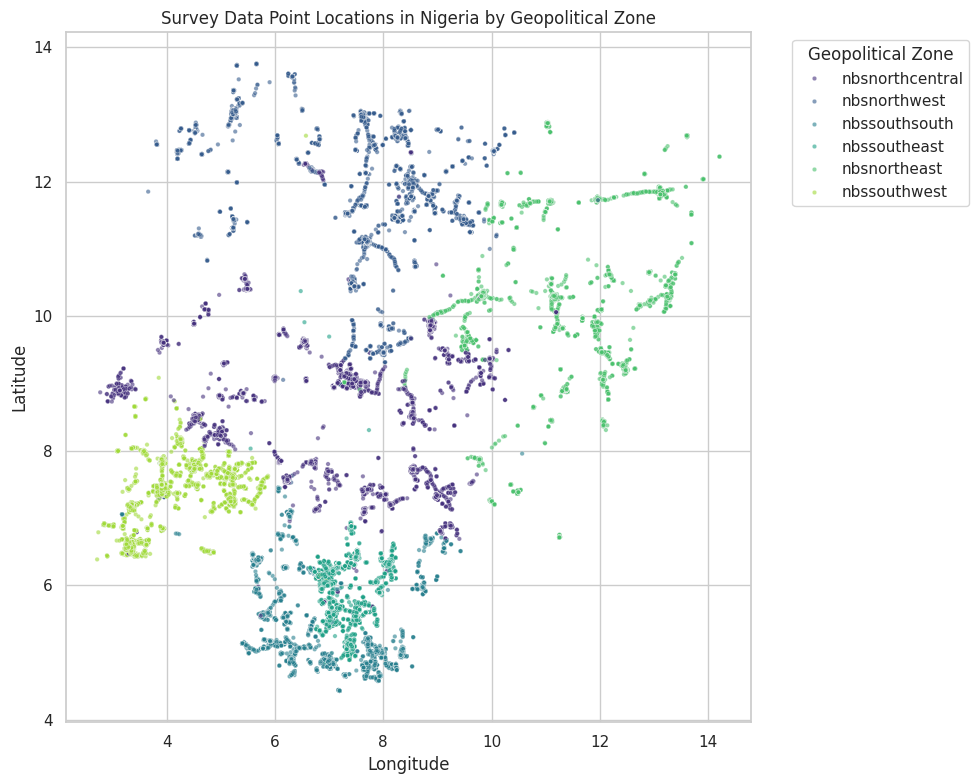

In [11]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_1,
    x='gps_longit',
    y='gps_latitu',
    hue='geopol_zon',
    palette='viridis',
    alpha=0.6,
    s=10
)
plt.title('Survey Data Point Locations in Nigeria by Geopolitical Zone')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Geopolitical Zone', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Visualizing Standardized Commodity Prices in `df_1`

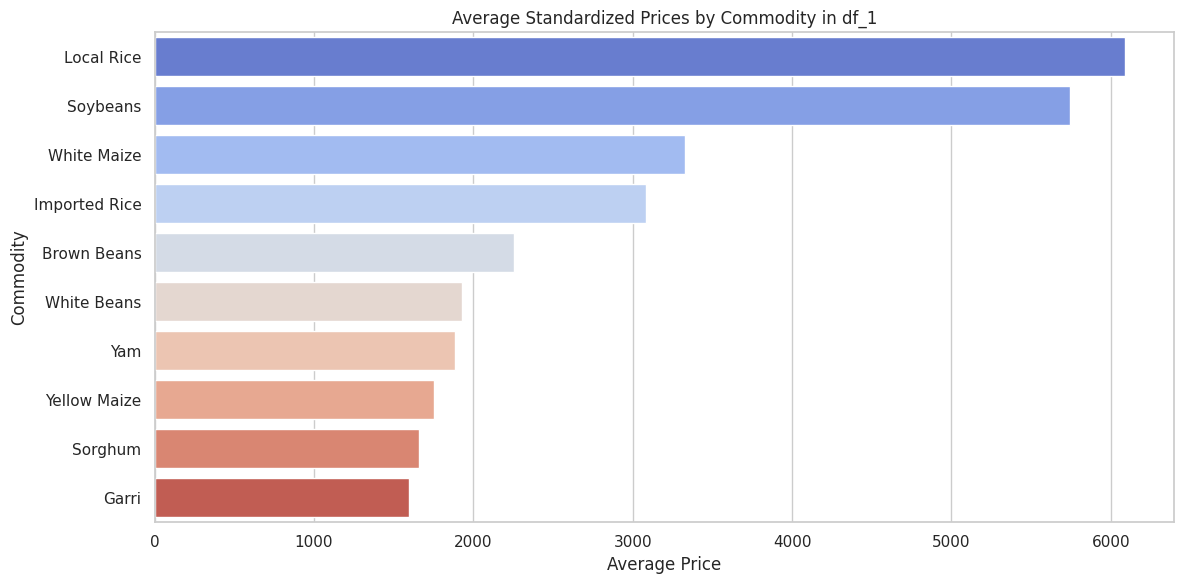

In [12]:
# Identify the standardized price columns (typically ending in _1 or _2 in df_1)
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Calculate mean prices for each commodity (ignoring missing values)
mean_prices = {commodity: df_1[col].mean() for commodity, col in price_cols.items()}
mean_prices_df = pd.DataFrame(list(mean_prices.items()), columns=['Commodity', 'Average Standardized Price']).sort_values(by='Average Standardized Price', ascending=False)

# Plot the average prices
plt.figure(figsize=(12, 6))
sns.barplot(data=mean_prices_df, x='Average Standardized Price', y='Commodity', palette='coolwarm', hue='Commodity', legend=False)
plt.title('Average Standardized Prices by Commodity in df_1')
plt.xlabel('Average Price')
plt.ylabel('Commodity')
plt.tight_layout()
plt.show()

### Average Price of Each Commodity by Geopolitical Zone (Community)

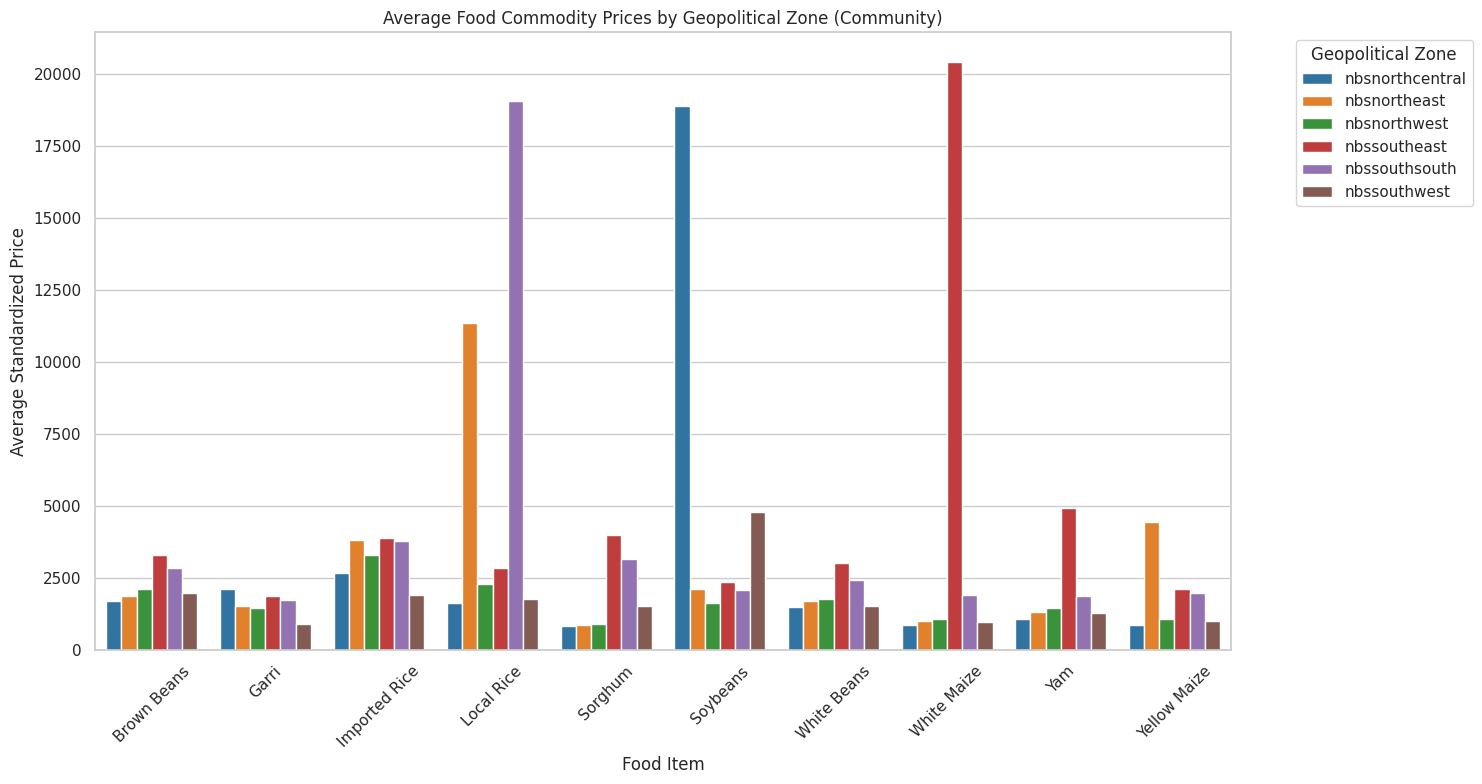

In [13]:
# Map columns to food items
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Create a melted dataframe of prices grouped by geopol_zon
price_data = []
for food, col in price_cols.items():
    if col in df_1.columns:
        temp_df = df_1[['geopol_zon', col]].dropna().copy()
        temp_df.rename(columns={col: 'Price'}, inplace=True)
        temp_df['Food Item'] = food
        price_data.append(temp_df)

prices_by_zone_df = pd.concat(price_data, ignore_index=True)

# Calculate mean values for plotting
grouped_df = prices_by_zone_df.groupby(['geopol_zon', 'Food Item'])['Price'].mean().reset_index()

# Create the visualization
plt.figure(figsize=(15, 8))
sns.barplot(
    data=grouped_df,
    x='Food Item',
    y='Price',
    hue='geopol_zon',
    palette='tab10'
)
plt.title('Average Food Commodity Prices by Geopolitical Zone (Community)')
plt.xlabel('Food Item')
plt.ylabel('Average Standardized Price')
plt.xticks(rotation=45)
plt.legend(title='Geopolitical Zone', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**ANALYZING MISSING VALUES**

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure date is parsed
df_1['date_parsed'] = pd.to_datetime(df_1['date'], errors='coerce')
df_1['year_month'] = df_1['date_parsed'].dt.to_period('M')

# Standardized price columns mapped to commodities
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Calculate the percentage of missing price entries per State and Month for each commodity
scarcity_records = []

for commodity, col in price_cols.items():
    # Group by state and month, calculate percentage of nulls in the price column
    grouped = df_1.groupby(['statelabel', 'year_month'])[col].apply(lambda x: x.isnull().mean() * 100).reset_index()
    grouped.rename(columns={col: 'missing_rate'}, inplace=True)
    grouped['commodity'] = commodity
    scarcity_records.append(grouped)

# Combine everything into one dataset
scarcity_df = pd.concat(scarcity_records, ignore_index=True)
scarcity_df['year_month_str'] = scarcity_df['year_month'].astype(str)

# Let's inspect the scarcity dataframe
display(scarcity_df.head())


,statelabel,year_month,missing_rate,commodity,year_month_str
0,ABIA,2024-11,0.000000,Yellow Maize,2024-11
1,ABIA,2024-12,0.569801,Yellow Maize,2024-12
2,ABIA,2025-01,0.312989,Yellow Maize,2025-01
3,ABIA,2025-02,0.142857,Yellow Maize,2025-02
4,ABIA,2025-03,0.128205,Yellow Maize,2025-03


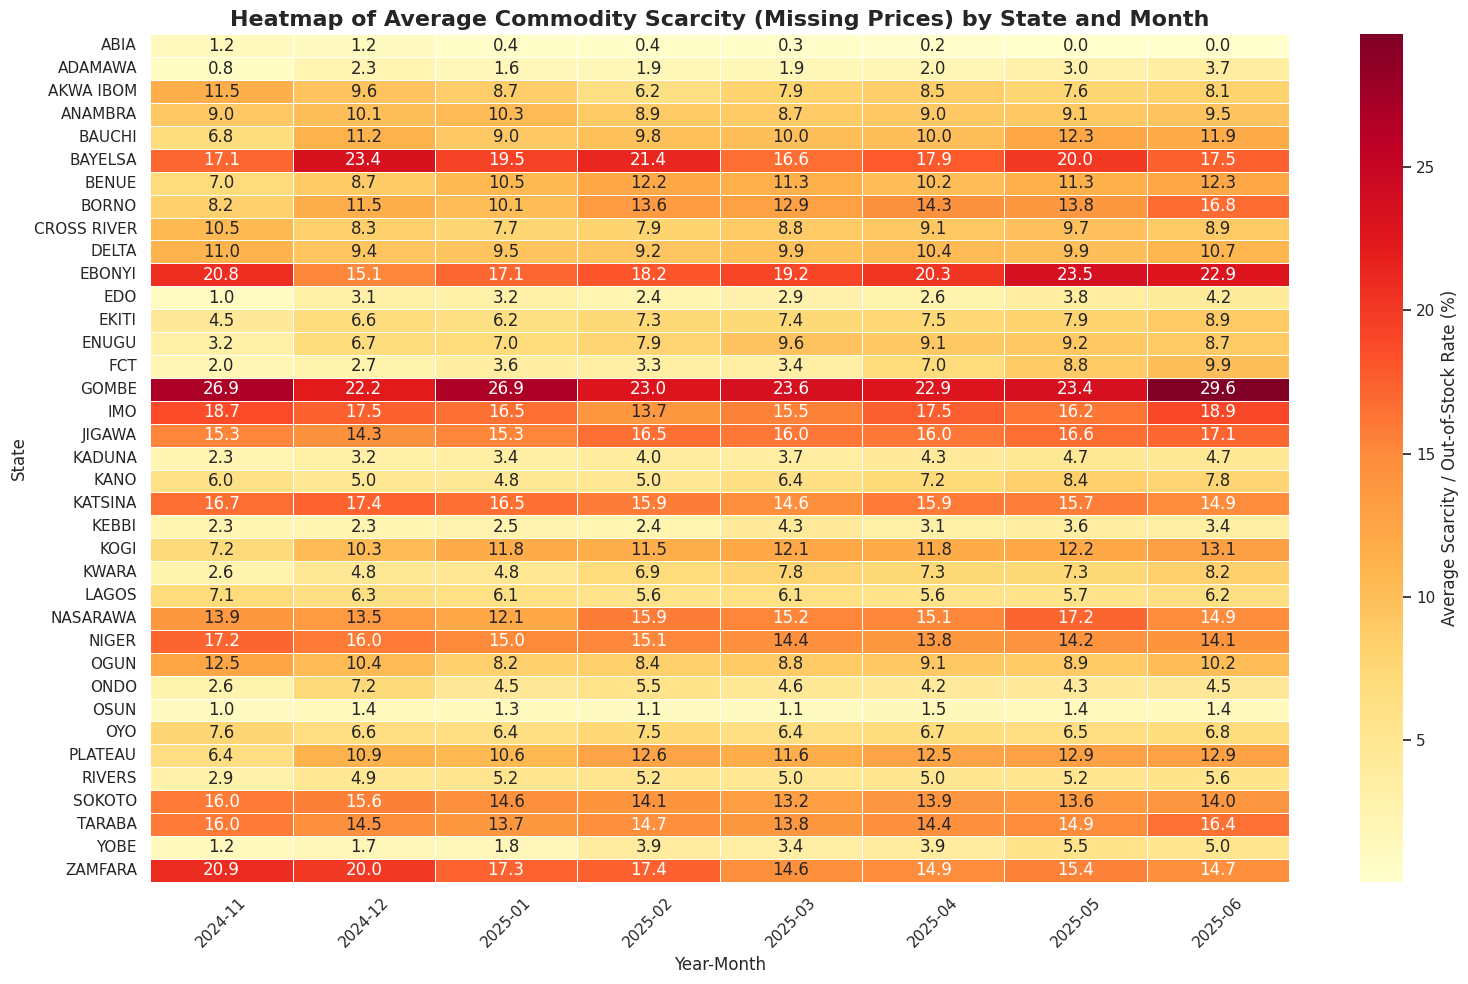

In [15]:
# Calculate overall commodity scarcity by state and time to detect global trends
# Pivot to create a State-Month matrix showing the average missing rate across all commodities
pivot_df = scarcity_df.pivot_table(
    index='statelabel',
    columns='year_month_str',
    values='missing_rate',
    aggfunc='mean'
)

plt.figure(figsize=(16, 10))
sns.heatmap(
    pivot_df,
    cmap='YlOrRd',
    annot=True,
    fmt=".1f",
    linewidths=.5,
    cbar_kws={'label': 'Average Scarcity / Out-of-Stock Rate (%)'}
)

plt.title('Heatmap of Average Commodity Scarcity (Missing Prices) by State and Month', fontsize=16, fontweight='bold')
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


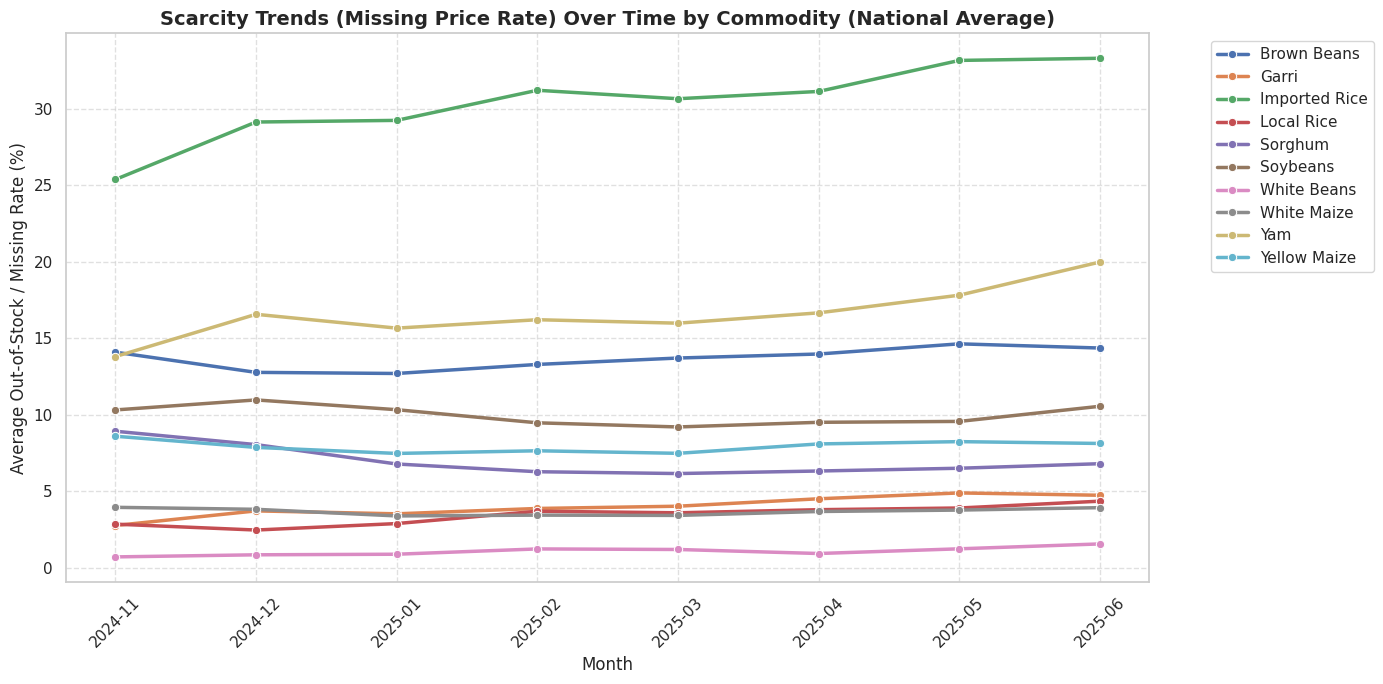

In [16]:
# Detailed view: Let's plot seasonal scarcity trends aggregated across all states for each individual commodity
plt.figure(figsize=(14, 7))
commodity_trends = scarcity_df.groupby(['year_month_str', 'commodity'])['missing_rate'].mean().reset_index()

sns.lineplot(
    data=commodity_trends,
    x='year_month_str',
    y='missing_rate',
    hue='commodity',
    marker='o',
    linewidth=2.5
)

plt.title('Scarcity Trends (Missing Price Rate) Over Time by Commodity (National Average)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Out-of-Stock / Missing Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [20]:
# Clean df_1 according to the specified steps
cols_to_drop = [
    'vc_id', 'gps_coords', 'consent', 'staff_vali', 'submissio',
    'lga', 'statecode1', 'zonecode1', 'geopol_zon', 'date_parsed',
    'price_ymai', 'price_wmai', 'price_sorg', 'price_impo', 'price_loca',
    'price_brow', 'price_whit', 'price_garr', 'price_yam', 'price_soya'
]

# Identify columns matching prefixes 'uom' and 'q'
uom_q_cols = [col for col in df_1.columns if col.startswith('uom_') or col.startswith('q_')]

# Combine all columns to drop that exist in the dataframe
final_drop_list = [col for col in (cols_to_drop + uom_q_cols) if col in df_1.columns]

df_1_cleaned = df_1.drop(columns=final_drop_list)

print(f"Original shape: {df_1.shape}")
print(f"Cleaned shape: {df_1_cleaned.shape}")
print("\nRemaining columns:")
print(df_1_cleaned.columns.tolist())


Original shape: (220214, 74)
Cleaned shape: (220214, 34)

Remaining columns:
['fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'market_tim', 'maize_yell', 'price_ym_1', 'maize_whit', 'price_wm_1', 'sorghum', 'price_so_1', 'imported_r', 'price_impo_1', 'local_rice', 'price_lo_1', 'brown_bean', 'price_br_1', 'white_bean', 'price_wh_1', 'garri_conf', 'price_ga_1', 'yam_confir', 'price_yam_', 'soyabeans', 'price_so_2', 'gps_latitu', 'gps_longit', 'gps_precis', 'count', 'year_month']


In [21]:
display(df_1_cleaned.head())

,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,maize_yell,...,price_ga_1,yam_confir,price_yam_,soyabeans,price_so_2,gps_latitu,gps_longit,gps_precis,count,year_month
0,0,12/1/2024,North Central,NASARAWA,KARU,Rural,City_market,Retail,10,Yes,...,642.857143,Yes,1700.000000,Yes,642.857143,9.026682,7.607355,NaN,1,2024-12
1,1,12/1/2024,North Central,NASARAWA,KARU,Rural,Local_village_market,Retail,15,Yes,...,714.285714,Yes,1300.000000,Yes,642.857143,9.026682,7.607355,NaN,1,2024-12
2,2,12/2/2024,North West,KADUNA,CHIKUN,Urban,Open air_or_covered market,Retail,20,Yes,...,928.571429,Yes,2166.666667,Yes,1071.428571,10.460725,7.447264,NaN,1,2024-12
3,3,12/2/2024,North Central,BENUE,OTUKPO,Urban,Local_village_market,Retail,15,Yes,...,577.777778,Yes,666.666667,Yes,1406.250000,7.192808,8.146351,NaN,1,2024-12
4,4,12/2/2024,North Central,BENUE,OTUKPO,Urban,Neighborhood_shops_kiosk,Retail,10,Yes,...,866.666667,Yes,500.000000,Yes,1562.500000,7.192811,8.146316,NaN,1,2024-12


### Inspecting Unique Values of Categorical Columns
We will retrieve all columns of type `object` (categorical) in `df_1_cleaned` and display their unique values along with their count to identify any inconsistencies.

In [23]:
# Select categorical (object) columns from df_1_cleaned
categorical_cols = df_1_cleaned.select_dtypes(include=['object']).columns.tolist()

print(f"Found {len(categorical_cols)} categorical columns: {categorical_cols}\n")

# Loop through each and show unique values
for col in categorical_cols:
    unique_vals = df_1_cleaned[col].dropna().unique()
    num_unique = len(unique_vals)
    print(f"=== Column: {col} ({num_unique} unique values) ===")
    if num_unique <= 30:
        print(sorted(list(unique_vals)))
    else:
        print(f"First 20 unique values: {sorted(list(unique_vals))[:20]}...")
    print("\n")

Found 17 categorical columns: ['date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'maize_yell', 'maize_whit', 'sorghum', 'imported_r', 'local_rice', 'brown_bean', 'white_bean', 'garri_conf', 'yam_confir', 'soyabeans']

=== Column: date (217 unique values) ===
First 20 unique values: ['1/1/2025', '1/10/2025', '1/11/2025', '1/12/2025', '1/13/2025', '1/14/2025', '1/15/2025', '1/16/2025', '1/17/2025', '1/18/2025', '1/19/2025', '1/2/2025', '1/20/2025', '1/21/2025', '1/22/2025', '1/23/2025', '1/24/2025', '1/25/2025', '1/26/2025', '1/27/2025']...


=== Column: zonelabel1 (6 unique values) ===
['North Central', 'North East', 'North West', 'South East', 'South South', 'South West']


=== Column: statelabel (37 unique values) ===
First 20 unique values: ['ABIA', 'ADAMAWA', 'AKWA IBOM', 'ANAMBRA', 'BAUCHI', 'BAYELSA', 'BENUE', 'BORNO', 'CROSS RIVER', 'DELTA', 'EBONYI', 'EDO', 'EKITI', 'ENUGU', 'FCT', 'GOMBE', 'IMO', 'JIGAWA', 'KADUNA', 'KANO']...


=== Column: l